In [41]:
# Data Handling
import pandas as pd
import numpy as np

#  Visualization
import seaborn as sns
import matplotlib.pyplot as plt

In [42]:
df = pd.read_csv("data/raw/photos.tsv000", sep="\t")
df.shape

(25000, 31)

In [43]:
pd.set_option("display.max_columns", None)

**1- EDA**

In [44]:
df.head(2)

,photo_id,photo_url,photo_image_url,photo_submitted_at,photo_featured,photo_width,photo_height,photo_aspect_ratio,photo_description,photographer_username,photographer_first_name,photographer_last_name,exif_camera_make,exif_camera_model,exif_iso,exif_aperture_value,exif_focal_length,exif_exposure_time,photo_location_name,photo_location_latitude,photo_location_longitude,photo_location_country,photo_location_city,stats_views,stats_downloads,ai_description,ai_primary_landmark_name,ai_primary_landmark_latitude,ai_primary_landmark_longitude,ai_primary_landmark_confidence,blur_hash
0,luPOnViYl7I,https://unsplash.com/photos/luPOnViYl7I,https://images.unsplash.com/photo-141613878277...,2014-11-16 11:48:22.003158,t,3110,2074,1.50,NaN,tanguysauvin,Tanguy,Sauvin,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1894069,11058,black water strider,NaN,NaN,NaN,NaN,LLIFY%Rp0Kxuof?bV@IU01-:%LM{
1,OdAqbedkfiA,https://unsplash.com/photos/OdAqbedkfiA,https://images.unsplash.com/28/tree-sky.jpg,2014-02-17 12:45:34,t,1500,2250,0.67,Conifers at the foot of snowy mountains,sylwiabartyzel,Sylwia,Bartyzel,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8288693,40344,silhouette of trees and snowy mountains,NaN,NaN,NaN,NaN,L-JI30ofRjRj~qfPayfQRjWBt7t7


In [45]:
df.isnull().sum()

photo_id                              0
photo_url                             0
photo_image_url                       0
photo_submitted_at                    0
photo_featured                        0
photo_width                           0
photo_height                          0
photo_aspect_ratio                    0
photo_description                 13949
photographer_username                 0
photographer_first_name               0
photographer_last_name             1668
exif_camera_make                   2872
exif_camera_model                  2916
exif_iso                           3279
exif_aperture_value                3671
exif_focal_length                  3553
exif_exposure_time                 3304
photo_location_name               14840
photo_location_latitude           17143
photo_location_longitude          17143
photo_location_country            15724
photo_location_city               18536
stats_views                           0
stats_downloads                       0


In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 31 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   photo_id                        25000 non-null  object 
 1   photo_url                       25000 non-null  object 
 2   photo_image_url                 25000 non-null  object 
 3   photo_submitted_at              25000 non-null  object 
 4   photo_featured                  25000 non-null  object 
 5   photo_width                     25000 non-null  int64  
 6   photo_height                    25000 non-null  int64  
 7   photo_aspect_ratio              25000 non-null  float64
 8   photo_description               11051 non-null  object 
 9   photographer_username           25000 non-null  object 
 10  photographer_first_name         25000 non-null  object 
 11  photographer_last_name          23332 non-null  object 
 12  exif_camera_make                

In [47]:
df["photo_location_country"].value_counts()

photo_location_country
United States     2472
Canada             466
United Kingdom     425
Australia          351
Italy              313
                  ... 
Brasov               1
Rhodes               1
Србија               1
Transilvania         1
Panamá               1
Name: count, Length: 443, dtype: int64

In [48]:
df.describe()

,photo_width,photo_height,photo_aspect_ratio,exif_iso,photo_location_latitude,photo_location_longitude,stats_views,stats_downloads,ai_primary_landmark_latitude,ai_primary_landmark_longitude,ai_primary_landmark_confidence
count,25000.000000,25000.000000,25000.000000,21721.000000,7857.000000,7857.000000,2.500000e+04,2.500000e+04,1316.000000,1316.000000,1316.000000
mean,4442.132240,4181.578720,1.151629,562.134846,33.511611,-19.077007,4.426662e+06,2.097857e+04,38.446652,-45.045024,18.678672
std,1354.360837,1385.791633,0.411964,1388.494452,25.597914,79.062258,4.520231e+07,8.350188e+04,21.963833,77.033844,28.393044
min,768.000000,563.000000,0.340000,0.000000,-82.862752,-178.139472,1.386700e+04,1.290000e+02,-51.466841,-159.725761,0.143585
25%,3456.000000,3264.000000,0.670000,100.000000,30.759658,-89.401230,4.427080e+05,2.179000e+03,37.277582,-116.510696,0.459758
50%,4074.000000,4000.000000,1.330000,200.000000,41.204380,-0.311950,8.410950e+05,4.646000e+03,43.216145,-72.545418,0.677706
75%,5472.000000,5184.000000,1.500000,400.000000,48.176667,14.550072,2.281087e+06,1.304200e+04,48.710016,10.136926,41.800691
max,16384.000000,16384.000000,4.130000,51200.000000,79.866667,178.085191,2.732294e+09,4.929347e+06,68.363153,176.087144,97.641426


In [49]:
missing = df.isnull().mean() * 100
missing.sort_values(ascending=False)

ai_primary_landmark_confidence    94.736
ai_primary_landmark_longitude     94.736
ai_primary_landmark_latitude      94.736
ai_primary_landmark_name          94.736
photo_location_city               74.144
photo_location_latitude           68.572
photo_location_longitude          68.572
photo_location_country            62.896
photo_location_name               59.360
photo_description                 55.796
exif_aperture_value               14.684
exif_focal_length                 14.212
exif_exposure_time                13.216
exif_iso                          13.116
exif_camera_model                 11.664
exif_camera_make                  11.488
photographer_last_name             6.672
blur_hash                          0.036
ai_description                     0.004
photo_url                          0.000
photographer_first_name            0.000
photographer_username              0.000
photo_aspect_ratio                 0.000
photo_height                       0.000
stats_views     

In [50]:
for col in ["exif_camera_make", "exif_iso", "exif_aperture_value", "exif_focal_length", "exif_exposure_time"]:
    print(df[col].value_counts().head(10))
    print()

exif_camera_make
Canon                          8433
NIKON CORPORATION              4548
SONY                           3861
FUJIFILM                       1483
DJI                             920
Apple                           624
Panasonic                       456
Hasselblad                      278
RICOH IMAGING COMPANY, LTD.     194
OLYMPUS CORPORATION             166
Name: count, dtype: int64

exif_iso
100.0     7286
200.0     2713
400.0     1959
800.0     1186
250.0      789
320.0      774
160.0      721
500.0      642
640.0      640
1600.0     606
Name: count, dtype: int64

exif_aperture_value
2.8    2933
5.6    1931
1.8    1703
4.0    1690
1.4    1085
2.2    1038
8.0     985
3.5     827
4.5     802
6.3     735
Name: count, dtype: int64

exif_focal_length
50.0     3037
35.0     1918
24.0     1197
18.0      836
70.0      712
55.0      700
85.0      672
16.0      538
200.0     500
4.7       489
Name: count, dtype: int64

exif_exposure_time
1/250     1343
1/200     1258
1/500    

**Keeping the columns that are useful for our need**

In [51]:
keepcol = [
    "photo_id", "photo_url", "photo_image_url", "photo_submitted_at", "photo_featured",
    "photo_width", "photo_height", "photo_aspect_ratio",
    "photographer_username", "exif_camera_make", "exif_camera_model", "exif_iso",
    "exif_aperture_value", "exif_focal_length", "exif_exposure_time",
    "photo_location_country", "stats_views", "stats_downloads", "ai_description"
]

In [52]:
clean_data = df[keepcol].copy()

In [53]:
clean_data.head(1)

,photo_id,photo_url,photo_image_url,photo_submitted_at,photo_featured,photo_width,photo_height,photo_aspect_ratio,photographer_username,exif_camera_make,exif_camera_model,exif_iso,exif_aperture_value,exif_focal_length,exif_exposure_time,photo_location_country,stats_views,stats_downloads,ai_description
0,luPOnViYl7I,https://unsplash.com/photos/luPOnViYl7I,https://images.unsplash.com/photo-141613878277...,2014-11-16 11:48:22.003158,t,3110,2074,1.5,tanguysauvin,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1894069,11058,black water strider


In [54]:
clean_data.shape

(25000, 19)

***2- Data Cleaning-Preprocessing***

In [55]:
clean_data.duplicated(subset="photo_id").sum()

0

In [56]:
clean_data = clean_data.rename(columns={
    "photo_submitted_at": "submitted_at",
    "photo_featured": "featured",
    "photo_width": "width",
    "photo_height": "height",
    "photo_aspect_ratio": "aspect_ratio",
    "photographer_username": "photographer",
    "exif_camera_make": "camera_make",
    "exif_camera_model": "camera_model",
    "exif_iso": "iso",
    "exif_aperture_value": "aperture",
    "exif_focal_length": "focal_length",
    "exif_exposure_time": "shutter",
    "photo_location_country": "country",
    "stats_views": "views",
    "stats_downloads": "downloads",
})
clean_data.columns

Index(['photo_id', 'photo_url', 'photo_image_url', 'submitted_at', 'featured',
       'width', 'height', 'aspect_ratio', 'photographer', 'camera_make',
       'camera_model', 'iso', 'aperture', 'focal_length', 'shutter', 'country',
       'views', 'downloads', 'ai_description'],
      dtype='object')

In [57]:
clean_data["has_exif"] = clean_data["camera_make"].notna()
clean_data["has_exif"].value_counts()

has_exif
True     22128
False     2872
Name: count, dtype: int64

In [58]:
for col in ["aperture", "focal_length"]:
    numbers = pd.to_numeric(clean_data[col], errors="coerce")
    bad = numbers.isna() & clean_data[col].notna()
    print(col, bad.sum())
    print(clean_data.loc[bad, col].value_counts().head())
    print()

aperture 25
aperture
undef    10
5,6       3
7,5       2
f/5       2
f4.0      1
Name: count, dtype: int64

focal_length 35
focal_length
50mm     5
35mm     4
85mm     3
50 mm    2
14mm     2
Name: count, dtype: int64



In [59]:
clean_data["brand"] = clean_data["camera_make"].str.lower().str.split().str[0]
clean_data["brand"].value_counts().head(20)

brand
canon         8436
nikon         4739
sony          3991
fujifilm      1519
dji            930
apple          624
panasonic      456
olympus        328
hasselblad     279
ricoh          199
samsung        112
leica           91
pentax          60
gopro           55
google          41
noritsu         37
fuji            35
huawei          33
xiaomi          21
zwo             15
Name: count, dtype: int64

In [60]:
clean_data.head()

,photo_id,photo_url,photo_image_url,submitted_at,featured,width,height,aspect_ratio,photographer,camera_make,camera_model,iso,aperture,focal_length,shutter,country,views,downloads,ai_description,has_exif,brand
0,luPOnViYl7I,https://unsplash.com/photos/luPOnViYl7I,https://images.unsplash.com/photo-141613878277...,2014-11-16 11:48:22.003158,t,3110,2074,1.50,tanguysauvin,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1894069,11058,black water strider,False,NaN
1,OdAqbedkfiA,https://unsplash.com/photos/OdAqbedkfiA,https://images.unsplash.com/28/tree-sky.jpg,2014-02-17 12:45:34,t,1500,2250,0.67,sylwiabartyzel,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8288693,40344,silhouette of trees and snowy mountains,False,NaN
2,w9UQ02x-QsU,https://unsplash.com/photos/w9UQ02x-QsU,https://images.unsplash.com/photo-141883330961...,2014-12-17 16:23:53.442485,t,3264,4896,0.67,jenellehayes,FUJIFILM,X-E1,200.0,7.1,37.4,1/350,NaN,2832184,26732,landscape photography of body of water near mo...,True,fujifilm
3,491PQ04olSg,https://unsplash.com/photos/491PQ04olSg,https://images.unsplash.com/photo-141389725556...,2014-10-21 13:16:22.143136,t,3901,2602,1.50,radel,NIKON CORPORATION,NIKON 1 V1,100.0,4.0,11.4,1/125,Italy,10035571,60182,landscape of house near electric post,True,nikon
4,_rZrkLPKPcU,https://unsplash.com/photos/_rZrkLPKPcU,https://images.unsplash.com/photo-143490956140...,2015-06-21 17:59:49.619717,t,5616,3744,1.50,anthonydelanoix,Canon,Canon EOS 5D Mark II,250.0,4.0,24.0,1/320,NaN,2609764,22351,bear on body of water,True,canon


In [61]:
# fix aperture format
clean_data["aperture"] = clean_data["aperture"].astype(str).str.replace(",", ".").str.replace("f/", "").str.replace("f", "")
clean_data["aperture"] = pd.to_numeric(clean_data["aperture"], errors="coerce")

In [62]:
# fix focal_length format
clean_data["focal_length"] = clean_data["focal_length"].astype(str).str.replace("mm", "").str.strip()
clean_data["focal_length"] = pd.to_numeric(clean_data["focal_length"], errors="coerce")

In [63]:
# making shutter speed to seconds
def to_seconds(x):
    try:
        if "/" in str(x):
            a, b = str(x).split("/")
            return float(a) / float(b)
        return float(x)
    except:
        return None

clean_data["shutter"] = clean_data["shutter"].apply(to_seconds)

In [64]:
# we can't have iso = 0
clean_data.loc[clean_data["iso"] == 0, "iso"] = np.nan

In [65]:
# impossible aperture values
clean_data.loc[(clean_data["aperture"] < 0.95) | (clean_data["aperture"] > 32), "aperture"] = np.nan

In [66]:
# a lens can't have 0mm focal length
clean_data.loc[clean_data["focal_length"] == 0, "focal_length"] = np.nan

In [67]:
# fixing date formating, and featured to be true or false 
clean_data["submitted_at"] = pd.to_datetime(clean_data["submitted_at"], format="mixed")
clean_data["featured"] = clean_data["featured"] == "t"

In [68]:
# some brands have the same name but different writing styles
clean_data["brand"] = clean_data["brand"].replace("fuji", "fujifilm")
# filling na values with unknown
clean_data["brand"] = clean_data["brand"].fillna("unknown")

In [69]:
phones = ["apple", "samsung", "google", "huawei", "xiaomi"]

def get_type(brand):
    if brand == "unknown":
        return "unknown"
    elif brand in phones:
        return "phone"
    elif brand == "dji":
        return "drone"
    else:
        return "camera"

clean_data["camera_type"] = clean_data["brand"].apply(get_type)

# DJI drones with Hasselblad cameras
is_drone = clean_data["camera_model"].str.contains("L1D|L2D", na=False)
clean_data.loc[is_drone, "camera_type"] = "drone"

clean_data["camera_type"].value_counts()

camera_type
camera     20104
unknown     2872
drone       1193
phone        831
Name: count, dtype: int64

In [70]:
# creating a new col "orientation" depending is the image landscape or portrait or square
def get_orientation(ratio):
    if ratio > 1.05:
        return "landscape"
    elif ratio < 0.95:
        return "portrait"
    else:
        return "square"

clean_data["orientation"] = clean_data["aspect_ratio"].apply(get_orientation)
clean_data["year"] = clean_data["submitted_at"].dt.year
clean_data["download_rate"] = clean_data["downloads"] / clean_data["views"]
clean_data["megapixels"] = clean_data["width"] * clean_data["height"] / 1_000_000

In [71]:
# filling the country nulls
clean_data["country"] = clean_data["country"].fillna("Unknown")

In [72]:
clean_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 26 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   photo_id         25000 non-null  object        
 1   photo_url        25000 non-null  object        
 2   photo_image_url  25000 non-null  object        
 3   submitted_at     25000 non-null  datetime64[ns]
 4   featured         25000 non-null  bool          
 5   width            25000 non-null  int64         
 6   height           25000 non-null  int64         
 7   aspect_ratio     25000 non-null  float64       
 8   photographer     25000 non-null  object        
 9   camera_make      22128 non-null  object        
 10  camera_model     22084 non-null  object        
 11  iso              21704 non-null  float64       
 12  aperture         21295 non-null  float64       
 13  focal_length     21372 non-null  float64       
 14  shutter          21672 non-null  float

In [73]:
clean_data.head()

,photo_id,photo_url,photo_image_url,submitted_at,featured,width,height,aspect_ratio,photographer,camera_make,camera_model,iso,aperture,focal_length,shutter,country,views,downloads,ai_description,has_exif,brand,camera_type,orientation,year,download_rate,megapixels
0,luPOnViYl7I,https://unsplash.com/photos/luPOnViYl7I,https://images.unsplash.com/photo-141613878277...,2014-11-16 11:48:22.003158,True,3110,2074,1.50,tanguysauvin,NaN,NaN,NaN,NaN,NaN,NaN,Unknown,1894069,11058,black water strider,False,unknown,unknown,landscape,2014,0.005838,6.450140
1,OdAqbedkfiA,https://unsplash.com/photos/OdAqbedkfiA,https://images.unsplash.com/28/tree-sky.jpg,2014-02-17 12:45:34.000000,True,1500,2250,0.67,sylwiabartyzel,NaN,NaN,NaN,NaN,NaN,NaN,Unknown,8288693,40344,silhouette of trees and snowy mountains,False,unknown,unknown,portrait,2014,0.004867,3.375000
2,w9UQ02x-QsU,https://unsplash.com/photos/w9UQ02x-QsU,https://images.unsplash.com/photo-141883330961...,2014-12-17 16:23:53.442485,True,3264,4896,0.67,jenellehayes,FUJIFILM,X-E1,200.0,7.1,37.4,0.002857,Unknown,2832184,26732,landscape photography of body of water near mo...,True,fujifilm,camera,portrait,2014,0.009439,15.980544
3,491PQ04olSg,https://unsplash.com/photos/491PQ04olSg,https://images.unsplash.com/photo-141389725556...,2014-10-21 13:16:22.143136,True,3901,2602,1.50,radel,NIKON CORPORATION,NIKON 1 V1,100.0,4.0,11.4,0.008000,Italy,10035571,60182,landscape of house near electric post,True,nikon,camera,landscape,2014,0.005997,10.150402
4,_rZrkLPKPcU,https://unsplash.com/photos/_rZrkLPKPcU,https://images.unsplash.com/photo-143490956140...,2015-06-21 17:59:49.619717,True,5616,3744,1.50,anthonydelanoix,Canon,Canon EOS 5D Mark II,250.0,4.0,24.0,0.003125,Unknown,2609764,22351,bear on body of water,True,canon,camera,landscape,2015,0.008564,21.026304


**Note for me:**
- "5,6" is how some European cameras write 5.6, so I swap the comma for a dot.
- errors="coerce" turns anything still broken (like "undef") into missing instead of crashing.
- 1/250 means the shutter was open for 1/250 of a second = 0.004 seconds.
- Some DJI drones use Hasselblad cameras, so I check the model name (L1D, L2D) to label them as drones.
- download_rate = downloads / views, how convincing a photo is, not just how many people saw it.

In [74]:
clean_data[["iso", "aperture", "focal_length", "shutter", "megapixels", "download_rate"]].describe()

,iso,aperture,focal_length,shutter,megapixels,download_rate
count,21704.000000,21295.000000,21372.000000,21672.000000,25000.000000,25000.000000
mean,562.575147,4.923949,67.044898,4.290962,18.972245,0.006912
std,1388.948981,3.715791,94.518967,111.469293,9.645742,0.008919
min,16.000000,0.950000,0.200000,0.000025,0.563000,0.000071
25%,100.000000,2.400000,23.000000,0.001250,12.192768,0.003816
50%,200.000000,4.000000,40.000000,0.004000,17.964296,0.005805
75%,400.000000,6.300000,70.000000,0.010000,24.000000,0.008277
max,51200.000000,32.000000,2032.000000,10800.000000,193.960959,0.851457


In [75]:
clean_data.describe()

,submitted_at,width,height,aspect_ratio,iso,aperture,focal_length,shutter,views,downloads,year,download_rate,megapixels
count,25000,25000.000000,25000.000000,25000.000000,21704.000000,21295.000000,21372.000000,21672.000000,2.500000e+04,2.500000e+04,25000.000000,25000.000000,25000.000000
mean,2018-12-09 18:16:10.411324928,4442.132240,4181.578720,1.151629,562.575147,4.923949,67.044898,4.290962,4.426662e+06,2.097857e+04,2018.468480,0.006912,18.972245
min,2013-06-09 13:57:48,768.000000,563.000000,0.340000,16.000000,0.950000,0.200000,0.000025,1.386700e+04,1.290000e+02,2013.000000,0.000071,0.563000
25%,2018-06-27 07:45:22.916183808,3456.000000,3264.000000,0.670000,100.000000,2.400000,23.000000,0.001250,4.427080e+05,2.179000e+03,2018.000000,0.003816,12.192768
50%,2019-04-27 14:25:56.688719104,4074.000000,4000.000000,1.330000,200.000000,4.000000,40.000000,0.004000,8.410950e+05,4.646000e+03,2019.000000,0.005805,17.964296
75%,2019-12-11 20:28:42.278301696,5472.000000,5184.000000,1.500000,400.000000,6.300000,70.000000,0.010000,2.281087e+06,1.304200e+04,2019.000000,0.008277,24.000000
max,2025-05-25 14:36:28.554051,16384.000000,16384.000000,4.130000,51200.000000,32.000000,2032.000000,10800.000000,2.732294e+09,4.929347e+06,2025.000000,0.851457,193.960959
std,NaN,1354.360837,1385.791633,0.411964,1388.948981,3.715791,94.518967,111.469293,4.520231e+07,8.350188e+04,1.724809,0.008919,9.645742


In [76]:
clean_data.to_csv("data/clean_data.csv", index=False)
clean_data.shape

(25000, 26)

In [77]:
clean_data.head()

,photo_id,photo_url,photo_image_url,submitted_at,featured,width,height,aspect_ratio,photographer,camera_make,camera_model,iso,aperture,focal_length,shutter,country,views,downloads,ai_description,has_exif,brand,camera_type,orientation,year,download_rate,megapixels
0,luPOnViYl7I,https://unsplash.com/photos/luPOnViYl7I,https://images.unsplash.com/photo-141613878277...,2014-11-16 11:48:22.003158,True,3110,2074,1.50,tanguysauvin,NaN,NaN,NaN,NaN,NaN,NaN,Unknown,1894069,11058,black water strider,False,unknown,unknown,landscape,2014,0.005838,6.450140
1,OdAqbedkfiA,https://unsplash.com/photos/OdAqbedkfiA,https://images.unsplash.com/28/tree-sky.jpg,2014-02-17 12:45:34.000000,True,1500,2250,0.67,sylwiabartyzel,NaN,NaN,NaN,NaN,NaN,NaN,Unknown,8288693,40344,silhouette of trees and snowy mountains,False,unknown,unknown,portrait,2014,0.004867,3.375000
2,w9UQ02x-QsU,https://unsplash.com/photos/w9UQ02x-QsU,https://images.unsplash.com/photo-141883330961...,2014-12-17 16:23:53.442485,True,3264,4896,0.67,jenellehayes,FUJIFILM,X-E1,200.0,7.1,37.4,0.002857,Unknown,2832184,26732,landscape photography of body of water near mo...,True,fujifilm,camera,portrait,2014,0.009439,15.980544
3,491PQ04olSg,https://unsplash.com/photos/491PQ04olSg,https://images.unsplash.com/photo-141389725556...,2014-10-21 13:16:22.143136,True,3901,2602,1.50,radel,NIKON CORPORATION,NIKON 1 V1,100.0,4.0,11.4,0.008000,Italy,10035571,60182,landscape of house near electric post,True,nikon,camera,landscape,2014,0.005997,10.150402
4,_rZrkLPKPcU,https://unsplash.com/photos/_rZrkLPKPcU,https://images.unsplash.com/photo-143490956140...,2015-06-21 17:59:49.619717,True,5616,3744,1.50,anthonydelanoix,Canon,Canon EOS 5D Mark II,250.0,4.0,24.0,0.003125,Unknown,2609764,22351,bear on body of water,True,canon,camera,landscape,2015,0.008564,21.026304


**3- Visualization**

In [78]:
sns.set_theme(style="whitegrid", palette=["#5B7562", "#C9A24D", "#AE6161", "#6C8699"])

**Univariate Analysis**

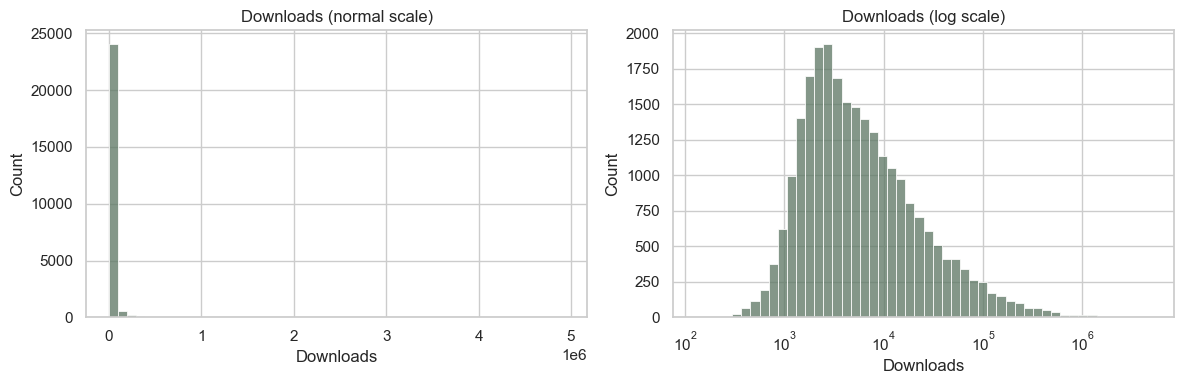

In [81]:
# 1. downloads: normal scale vs log scale
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(clean_data["downloads"], bins=50, ax=axes[0])
axes[0].set_title("Downloads (normal scale)")
axes[0].set_xlabel("Downloads")

sns.histplot(clean_data["downloads"], bins=50, log_scale=True, ax=axes[1])
axes[1].set_title("Downloads (log scale)")
axes[1].set_xlabel("Downloads")

plt.tight_layout()
plt.show()

In [82]:
# how unequal is popularity?
top_1_percent = clean_data["downloads"].sort_values(ascending=False).head(250).sum()
share = top_1_percent / clean_data["downloads"].sum() * 100
print("Top 1% of photos (250) get", round(share, 1), "% of all downloads")

print("Mean downloads:  ", round(clean_data["downloads"].mean()))
print("Median downloads:", round(clean_data["downloads"].median()))

Top 1% of photos (250) get 30.0 % of all downloads
Mean downloads:   20979
Median downloads: 4646


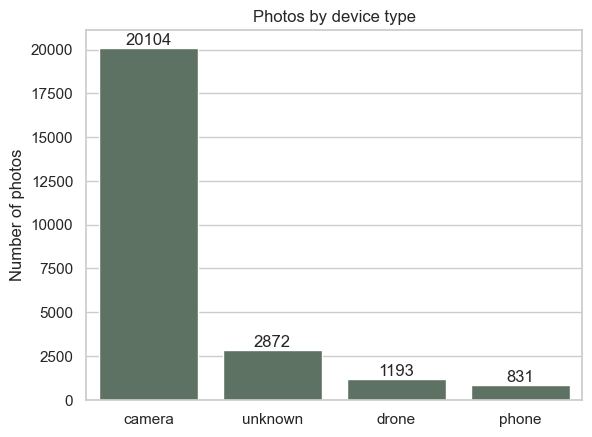

In [84]:
# 2. how many photos come from each device type
order = clean_data["camera_type"].value_counts().index

ax = sns.countplot(data=clean_data, x="camera_type", order=order)
ax.bar_label(ax.containers[0])
plt.title("Photos by device type")
plt.xlabel("")
plt.ylabel("Number of photos")

plt.show()

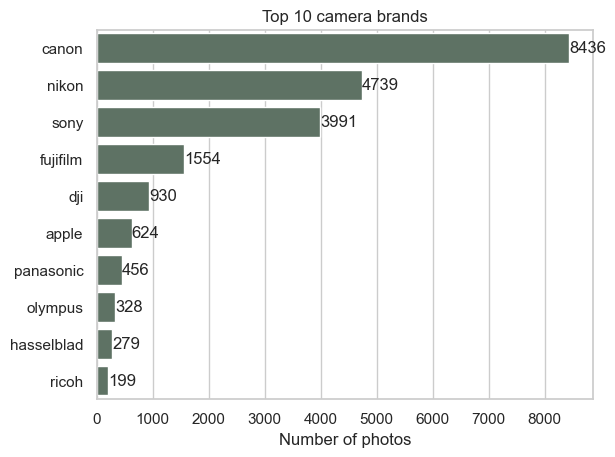

In [85]:
# 3. top 10 camera brands
known = clean_data[clean_data["brand"] != "unknown"]
top_brands = known["brand"].value_counts().head(10).index

ax = sns.countplot(data=known[known["brand"].isin(top_brands)], y="brand", order=top_brands)
ax.bar_label(ax.containers[0])
plt.title("Top 10 camera brands")
plt.xlabel("Number of photos")
plt.ylabel("")

plt.show()

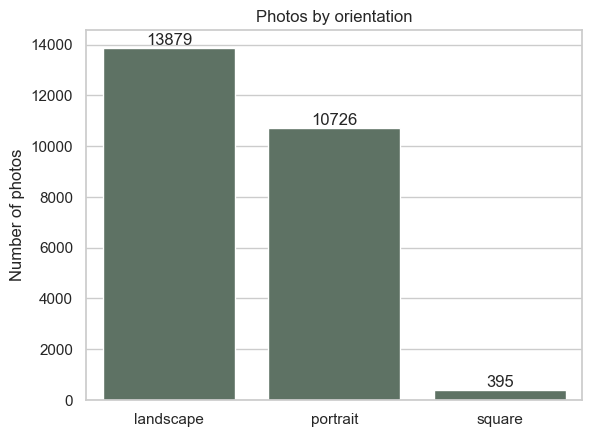

In [87]:
# 4. landscape vs portrait vs square
order = clean_data["orientation"].value_counts().index

ax = sns.countplot(data=clean_data, x="orientation", order=order)
ax.bar_label(ax.containers[0])
plt.title("Photos by orientation")
plt.xlabel("")
plt.ylabel("Number of photos")

plt.show()

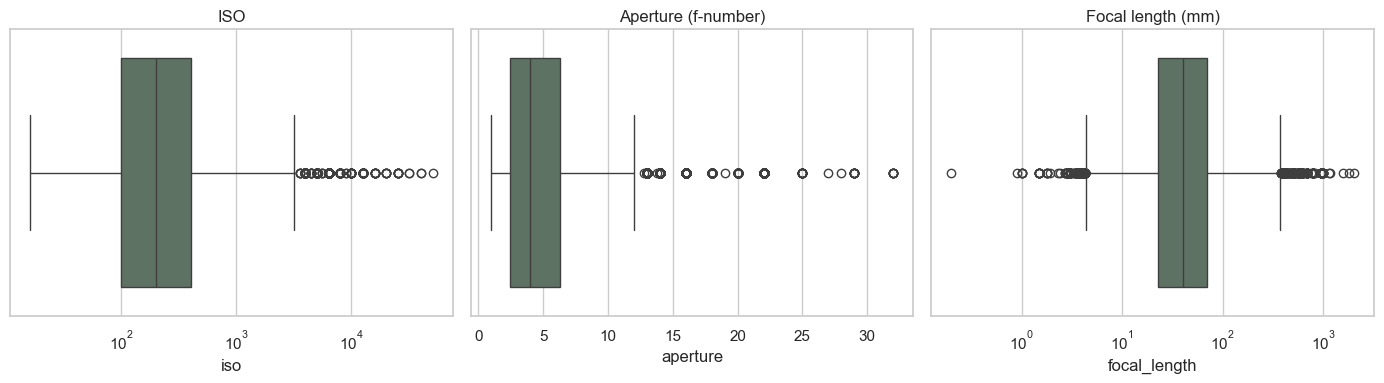

In [89]:
# 5. boxplots of the camera settings (to spot outliers)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.boxplot(x=clean_data["iso"], log_scale=True, ax=axes[0])
axes[0].set_title("ISO")

sns.boxplot(x=clean_data["aperture"], ax=axes[1])
axes[1].set_title("Aperture (f-number)")

sns.boxplot(x=clean_data["focal_length"], log_scale=True, ax=axes[2])
axes[2].set_title("Focal length (mm)")

plt.tight_layout()
plt.show()

In [90]:
# the extreme values
print("Highest ISO:", clean_data["iso"].max())
print("Longest shutter (seconds):", clean_data["shutter"].max())
print("Longest focal length (mm):", clean_data["focal_length"].max())
print("Highest download rate:", round(clean_data["download_rate"].max(), 3))

# what are these extreme photos?
clean_data.sort_values("shutter", ascending=False)[["brand", "camera_model", "shutter", "focal_length", "ai_description"]].head()

Highest ISO: 51200.0
Longest shutter (seconds): 10800.0
Longest focal length (mm): 2032.0
Highest download rate: 0.851


,brand,camera_model,shutter,focal_length,ai_description
6792,qhy,268C,10800.0,1600.0,blue brown and yellow abstract painting
13987,canon,Canon EOS REBEL T3i,9415.0,18.0,Concentric circles created by stars moving thr...
23670,nikon,D810,4050.0,400.0,white and pink galaxy illustration
13814,nikon,D750,3600.0,1800.0,"blue, grey, and purple nebula"
17251,nikon,NIKON D750,2194.0,17.0,timelapse photography of light


In [91]:
clean_data.iloc[6792]

photo_id                                                 kZH8X0q4Nvo
photo_url                    https://unsplash.com/photos/kZH8X0q4Nvo
photo_image_url    https://images.unsplash.com/photo-159508840219...
submitted_at                              2020-07-18 16:08:32.725309
featured                                                        True
width                                                          11361
height                                                          8697
aspect_ratio                                                    1.31
photographer                                               liuchen37
camera_make                                                  QHY CCD
camera_model                                                    268C
iso                                                              NaN
aperture                                                         7.0
focal_length                                                  1600.0
shutter                           

In [94]:
# download outliers using the IQR rule
q1 = clean_data["downloads"].quantile(0.25)
q3 = clean_data["downloads"].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
lower = q1 - 1.5 * (q3 - q1)

outliers = clean_data[clean_data["downloads"] > upper]
print("Upper limit:", round(upper))
print("Lower limit:", round(lower))
print(len(outliers), "photos are download outliers =", round(len(outliers) / len(clean_data) * 100, 1), "%")

Upper limit: 29336
Lower limit: -14116
3157 photos are download outliers = 12.6 %


**Bivariate & Multivariate Analysis**

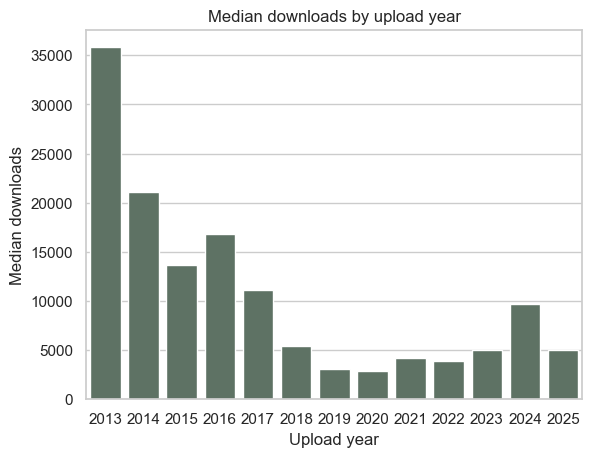

year
2013       71
2014      450
2015     1712
2016     1431
2017     1907
2018     3107
2019    10694
2020     5018
2021      203
2022      101
2023       55
2024        3
2025      248
Name: count, dtype: int64

In [96]:
# 6. older photos had more time to collect downloads
year_med = clean_data.groupby("year")["downloads"].median()

ax = sns.barplot(x=year_med.index, y=year_med.values)
plt.title("Median downloads by upload year")
plt.xlabel("Upload year")
plt.ylabel("Median downloads")

plt.show()

clean_data["year"].value_counts().sort_index()

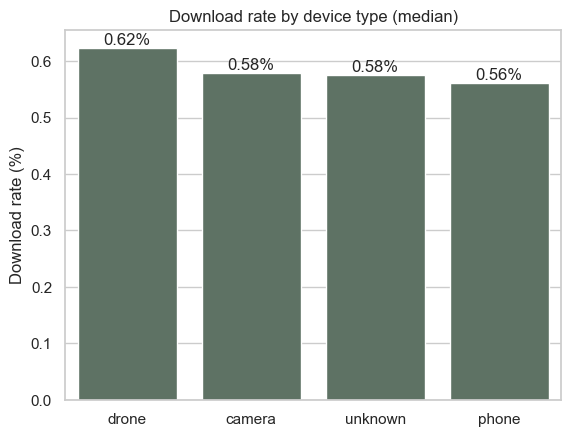

In [98]:
# 7. phone vs camera vs drone: how often a viewer downloads
rate_by_type = clean_data.groupby("camera_type")["download_rate"].median() * 100
rate_by_type = rate_by_type.sort_values(ascending=False)

ax = sns.barplot(x=rate_by_type.index, y=rate_by_type.values)
ax.bar_label(ax.containers[0], fmt="%.2f%%")
plt.title("Download rate by device type (median)")
plt.xlabel("")
plt.ylabel("Download rate (%)")

plt.show()

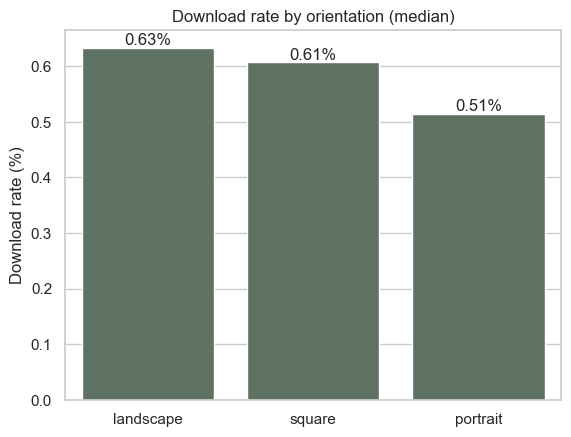

In [100]:
# 8. orientation vs download rate
rate_by_orient = clean_data.groupby("orientation")["download_rate"].median() * 100
rate_by_orient = rate_by_orient.sort_values(ascending=False)

ax = sns.barplot(x=rate_by_orient.index, y=rate_by_orient.values)
ax.bar_label(ax.containers[0], fmt="%.2f%%")
plt.title("Download rate by orientation (median)")
plt.xlabel("")
plt.ylabel("Download rate (%)")

plt.show()

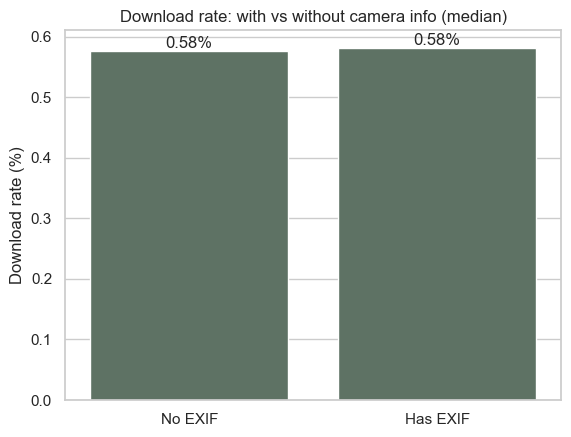

In [102]:
# 9. photos with camera info vs without
exif_rate = clean_data.groupby("has_exif")["download_rate"].median() * 100
exif_rate.index = ["No EXIF", "Has EXIF"]

ax = sns.barplot(x=exif_rate.index, y=exif_rate.values)
ax.bar_label(ax.containers[0], fmt="%.2f%%")
plt.title("Download rate: with vs without camera info (median)")
plt.xlabel("")
plt.ylabel("Download rate (%)")

plt.show()

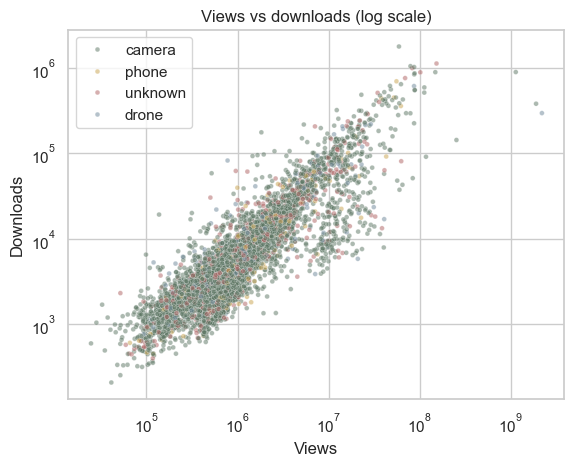

In [104]:
# 10. views vs downloads (random photos so the dots don't hide each other)
sample = clean_data.sample(5000, random_state=42)

sns.scatterplot(data=sample, x="views", y="downloads", hue="camera_type", alpha=0.5, s=12)
plt.xscale("log")
plt.yscale("log")
plt.title("Views vs downloads (log scale)")
plt.xlabel("Views")
plt.ylabel("Downloads")
plt.legend(title="")

plt.show()

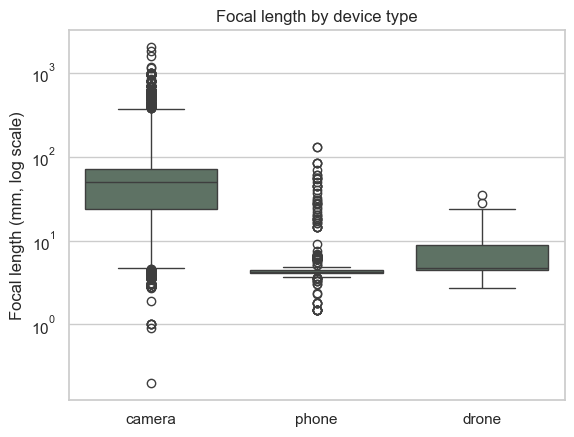

camera_type
camera    50.0
drone      4.7
phone      4.2
Name: focal_length, dtype: float64

In [106]:
# 11. the focal length trap: phones and cameras use different scales
devices = clean_data[clean_data["camera_type"] != "unknown"]

sns.boxplot(data=devices, x="camera_type", y="focal_length", log_scale=True)
plt.title("Focal length by device type")
plt.xlabel("")
plt.ylabel("Focal length (mm, log scale)")

plt.show()

devices.groupby("camera_type")["focal_length"].median()

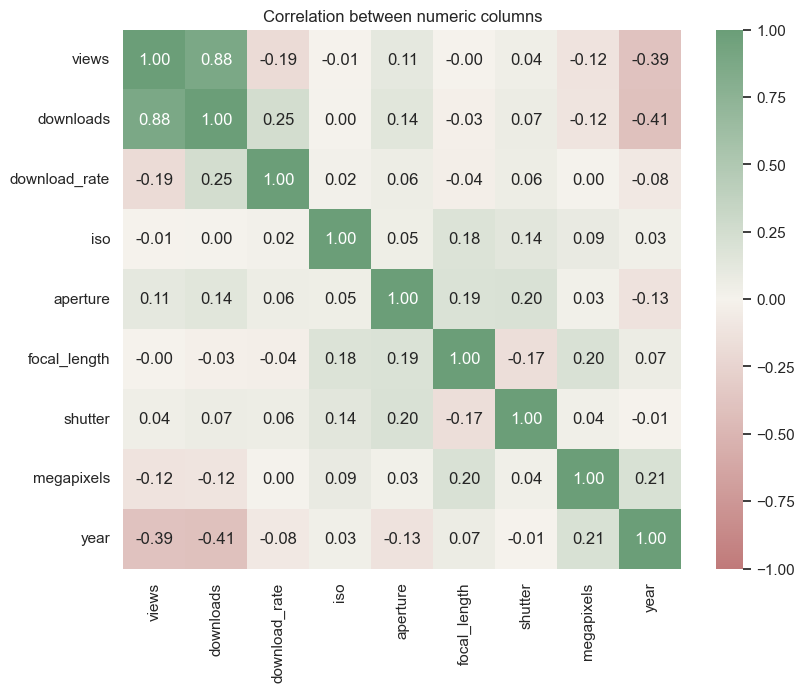

In [110]:
# 12. correlation heatmap
from matplotlib.colors import LinearSegmentedColormap

num_cols = ["views", "downloads", "download_rate", "iso", "aperture",
            "focal_length", "shutter", "megapixels", "year"]

corr = clean_data[num_cols].corr(method="spearman")
cmap = LinearSegmentedColormap.from_list("muted", ["#C07A7A", "#F5F2EC", "#6B9E78"])

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=cmap, vmin=-1, vmax=1)
plt.title("Correlation between numeric columns")

plt.show()

**4- Insights Summary**

**Patterns**
- 80.4% of photos were taken with a camera and only 3.3% with a phone. Even drones (4.8%) beat phones.
- Canon, Nikon and Sony make up 68.7% of all photos.
- The most common settings are ISO 100, f/2.8, 50mm and 1/250 s.

**Popularity is unequal**
- The typical photo gets 4,646 downloads, but the average is 20,979 because a few viral photos (up to 4.93 million downloads) pull it up.

**Outliers**
- Extreme values like ISO 51,200, a 3 hour shutter and a 2,032mm lens are real night, long-exposure and telescope shots, so they were kept.
- Impossible values (ISO 0, 0mm focal length) were removed.

**Key takeaways**
- Download rate (downloads / views) is fairer than raw downloads, since older photos had more time to collect downloads.
- Missing camera info was kept as "unknown" instead of filling it with fake values.
- Phone and camera focal lengths can't be compared directly because phone sensors are much smaller.

**5- Predictive Model**

**Classification model**

In [112]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 1 = high download rate (above median), 0 = low
model_data = clean_data.copy()
model_data["high_rate"] = (model_data["download_rate"] > model_data["download_rate"].median()).astype(int)

# turn text columns into 0/1 columns
X = pd.get_dummies(model_data[["orientation", "camera_type", "year", "megapixels"]], dtype=int)
y = model_data["high_rate"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X_train, y_train)

print("Model accuracy:", round(accuracy_score(y_test, model.predict(X_test)) * 100, 1), "%")
print("Random guess:   50 %")

Model accuracy: 58.5 %
Random guess:   50 %


In [113]:
# which features did the tree use most?
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
importance.head(8)

year                     0.533970
orientation_portrait     0.444197
megapixels               0.021833
orientation_landscape    0.000000
orientation_square       0.000000
camera_type_camera       0.000000
camera_type_drone        0.000000
camera_type_phone        0.000000
dtype: float64

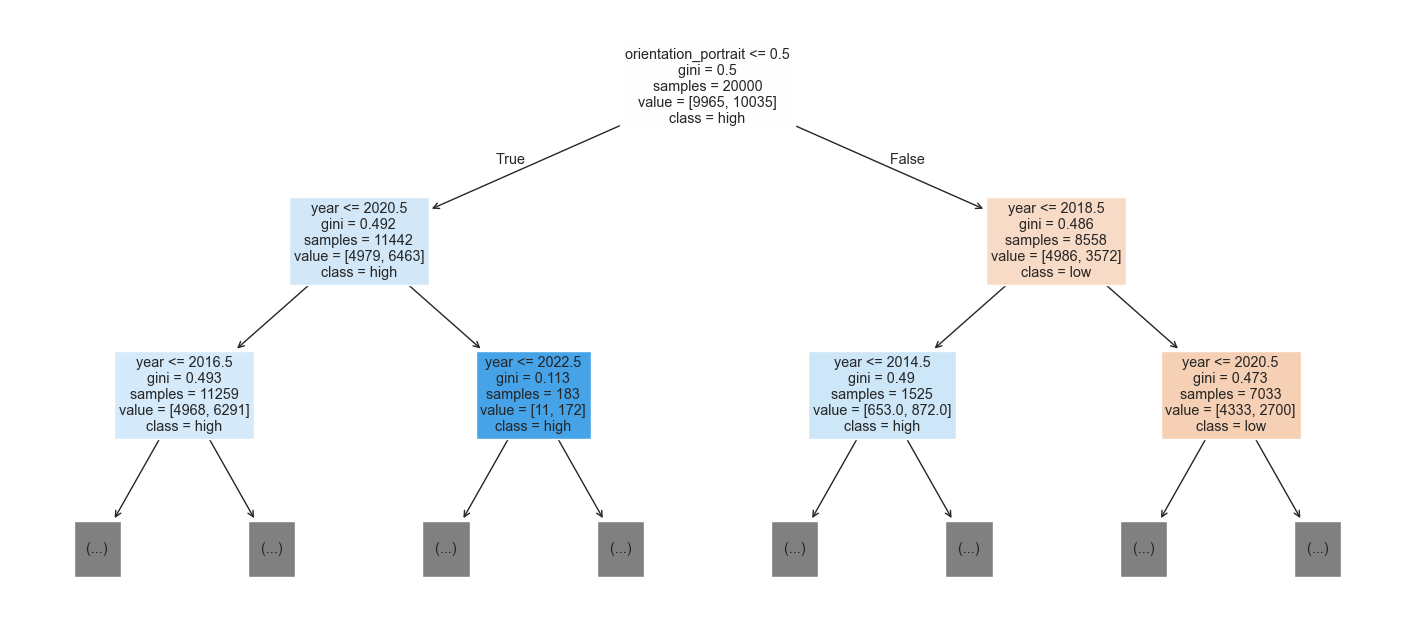

In [114]:
# the first questions the tree asks
plt.figure(figsize=(18, 8))
plot_tree(model, feature_names=X.columns, class_names=["low", "high"], filled=True, max_depth=2)
plt.show()

**7- Model Evaluation**

In [115]:
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import cross_val_score, KFold

y_pred = model.predict(X_test)

# 1. train vs test accuracy: is the model memorizing?
print("Train accuracy:", round(accuracy_score(y_train, model.predict(X_train)) * 100, 1), "%")
print("Test accuracy: ", round(accuracy_score(y_test, y_pred) * 100, 1), "%")

Train accuracy: 59.1 %
Test accuracy:  58.5 %


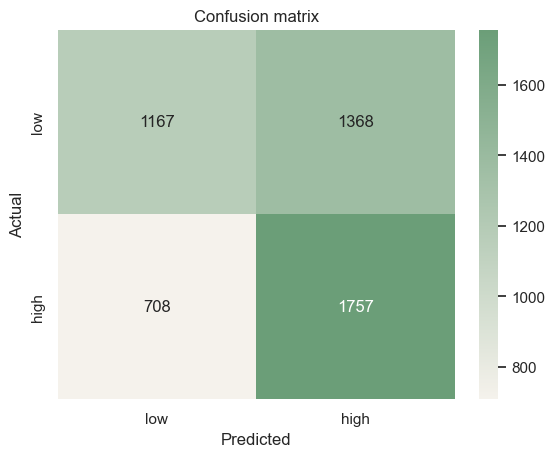

In [116]:
# 2. confusion matrix: where is it right and wrong?
cm = confusion_matrix(y_test, y_pred)
cm_colors = LinearSegmentedColormap.from_list("sage", ["#F5F2EC", "#6B9E78"])

sns.heatmap(cm, annot=True, fmt="d", cmap=cm_colors,
            xticklabels=["low", "high"], yticklabels=["low", "high"])
plt.title("Confusion matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [117]:
# 3. precision, recall and f1 for each class
print(classification_report(y_test, y_pred, target_names=["low", "high"]))

              precision    recall  f1-score   support

         low       0.62      0.46      0.53      2535
        high       0.56      0.71      0.63      2465

    accuracy                           0.58      5000
   macro avg       0.59      0.59      0.58      5000
weighted avg       0.59      0.58      0.58      5000



In [118]:
# 4. cross-validation: test on 5 different splits, not just one
folds = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, X, y, cv=folds)

print("Accuracy on each split:", (scores * 100).round(1))
print("Average:", round(scores.mean() * 100, 1), "%")

Accuracy on each split: [58.5 59.5 58.6 58.  58.7]
Average: 58.7 %
